# CIFAR-10 이미지 분류: K-최근접 이웃(KNN)

**목표:** KNN을 직접 구현하고, `k`와 거리 척도(L1/L2)를 비교합니다. 학습 데이터에 5-fold 교차검증을 적용하고, 선택한 설정을 테스트 데이터에서 정확도·정밀도·재현율·F1 점수로 평가합니다.

**실행 순서:** 런타임 연결 → 아래 데이터 경로 설정 → 모든 셀 실행. 이 노트북은 데이터를 다운로드하지 않습니다.

**Colab으로 데이터 옮기기:** 로컬의 `cifar-10-python.tar.gz`를 Colab의 파일 패널에서 `/content/`에 업로드하거나 Google Drive에 올리세요. 이미 추출한 `cifar-10-batches-py` 폴더를 Drive에 올려도 됩니다. Drive를 쓸 때는 아래에서 직접 마운트한 뒤 경로 변수를 바꾸세요. Colab 런타임은 내 컴퓨터의 폴더를 자동으로 볼 수 없습니다.

**데이터 범위:** 기본 설정은 공식 학습 이미지 50,000장과 테스트 이미지 10,000장을 모두 사용합니다. 5-fold 교차검증의 각 fold는 학습 40,000장과 검증 10,000장으로 구성됩니다. 원본 픽셀 KNN은 계산량이 매우 크므로 Colab의 **GPU 런타임**을 권장합니다(런타임 → 런타임 유형 변경 → GPU). GPU를 사용할 수 없으면 NumPy CPU 방식으로 실행되지만 수 시간이 걸릴 수 있습니다.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. 라이브러리와 실험 설정


In [2]:
from pathlib import Path
import pickle
import tarfile
import shutil
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import torch
except ImportError:
    torch = None
from IPython.display import display

SEED = 42
TRAIN_SAMPLES = 50_000
TEST_SAMPLES = 10_000
N_FOLDS = 5
K_VALUES = (1, 3, 5, 7, 9, 11, 15, 21, 31, 51)
DISTANCE_METRICS = ("L1", "L2")
QUERY_BATCH_SIZE = 64
TRAIN_BATCH_SIZE = 4_096
USE_GPU = torch is not None and torch.cuda.is_available()
print('거리 계산 장치:', 'GPU' if USE_GPU else 'CPU')

# Colab에서 압축 파일을 /content에 업로드했다면 그대로 사용합니다.
# Drive에 저장했다면 Drive를 직접 마운트하고 아래 두 경로 중 해당 경로를 수정하세요.
DATA_DIR = Path("/content/drive/MyDrive/CV/cifar-10-batches-py")
ARCHIVE_PATH = Path("/content/cifar-10-python.tar.gz")

assert TRAIN_SAMPLES % 10 == 0 and TEST_SAMPLES % 10 == 0
assert all(k > 0 for k in K_VALUES) and max(K_VALUES) < TRAIN_SAMPLES * (N_FOLDS - 1) // N_FOLDS


거리 계산 장치: GPU


## 2. 데이터 읽기

압축 파일을 지정한 경우 Colab 안에서만 풉니다. 공식 학습 배치 5개와 테스트 배치 1개를 각각 읽고, 데이터 형태를 확인합니다. `pickle` 파일은 신뢰할 수 있는 CIFAR-10 배포 파일만 사용하세요.


In [3]:
required_files = {"batches.meta", "readme.html", "test_batch", *(f"data_batch_{i}" for i in range(1, 6))}
if not DATA_DIR.is_dir():
    if not ARCHIVE_PATH.is_file():
        raise FileNotFoundError(
            f"데이터를 찾지 못했습니다. {DATA_DIR} 폴더 또는 {ARCHIVE_PATH} 파일을 Colab에 준비하세요."
        )
    target_parent = DATA_DIR.parent
    target_parent.mkdir(parents=True, exist_ok=True)
    with tarfile.open(ARCHIVE_PATH, "r:gz") as archive:
        members = [m for m in archive.getmembers() if m.isfile()]
        names = {Path(m.name).name for m in members}
        if names != required_files or any(Path(m.name).parent.name != "cifar-10-batches-py" for m in members):
            raise ValueError("예상한 CIFAR-10 Python 압축 파일 구조가 아닙니다.")
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        for member in members:
            with archive.extractfile(member) as src, (DATA_DIR / Path(member.name).name).open("wb") as dst:
                shutil.copyfileobj(src, dst)

missing = required_files - {p.name for p in DATA_DIR.iterdir() if p.is_file()}
if missing:
    raise FileNotFoundError(f"배치 파일 누락: {sorted(missing)}")

def read_pickle(path):
    with path.open("rb") as stream:
        return pickle.load(stream, encoding="bytes")

def read_batch(path):
    batch = read_pickle(path)
    images = batch[b"data"]
    labels = np.asarray(batch[b"labels"], dtype=np.int64)
    assert images.shape == (10_000, 3_072) and images.dtype == np.uint8
    assert labels.shape == (10_000,)
    return images, labels

train_parts = [read_batch(DATA_DIR / f"data_batch_{i}") for i in range(1, 6)]
X_train_all = np.concatenate([part[0] for part in train_parts])
y_train_all = np.concatenate([part[1] for part in train_parts])
X_test_all, y_test_all = read_batch(DATA_DIR / "test_batch")
class_names = [name.decode("utf-8") for name in read_pickle(DATA_DIR / "batches.meta")[b"label_names"]]
assert X_train_all.shape == (50_000, 3_072) and X_test_all.shape == (10_000, 3_072)
assert np.array_equal(np.bincount(y_train_all, minlength=10), np.full(10, 5_000))
assert np.array_equal(np.bincount(y_test_all, minlength=10), np.full(10, 1_000))
print("학습:", X_train_all.shape, "테스트:", X_test_all.shape)
print("클래스:", class_names)


학습: (50000, 3072) 테스트: (10000, 3072)
클래스: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 3. 데이터 준비

기본 설정에서는 공식 학습·테스트 데이터를 모두 사용합니다. 테스트 데이터는 하이퍼파라미터 선택에 사용하지 않습니다. 픽셀은 `float32`로 변환하고 0~1로 스케일링하여 `uint8` 뺄셈의 오버플로를 피합니다.


In [4]:
def stratified_sample_indices(labels, n_samples, seed):
    classes = np.unique(labels)
    if n_samples % len(classes):
        raise ValueError("표본 수는 클래스 수의 배수여야 합니다.")
    per_class = n_samples // len(classes)
    rng = np.random.default_rng(seed)
    chosen = []
    for label in classes:
        pool = np.flatnonzero(labels == label)
        if len(pool) < per_class:
            raise ValueError("요청한 표본 수가 클래스의 데이터 수보다 많습니다.")
        chosen.append(rng.choice(pool, size=per_class, replace=False))
    return rng.permutation(np.concatenate(chosen))

train_indices = stratified_sample_indices(y_train_all, TRAIN_SAMPLES, SEED)
test_indices = stratified_sample_indices(y_test_all, TEST_SAMPLES, SEED + 1)
X_train = X_train_all[train_indices].astype(np.float32) / 255.0
y_train = y_train_all[train_indices]
X_test = X_test_all[test_indices].astype(np.float32) / 255.0
y_test = y_test_all[test_indices]
del train_parts, X_train_all, y_train_all, X_test_all, y_test_all
print("전체 실험 데이터:", X_train.shape, X_test.shape)
print("학습 클래스별 수:", np.bincount(y_train, minlength=10))
print("테스트 클래스별 수:", np.bincount(y_test, minlength=10))


전체 실험 데이터: (50000, 3072) (10000, 3072)
학습 클래스별 수: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
테스트 클래스별 수: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


## 4. KNN 직접 구현

- L1 거리: 픽셀별 절댓값 차이의 합
- L2 거리: 픽셀별 차이 제곱의 합의 제곱근. CPU 경로는 **제곱 L2**, GPU 경로는 L2를 계산합니다. 제곱근은 거리의 순서를 바꾸지 않으므로 가장 가까운 이웃은 같습니다.
- 같은 거리 행렬에서 여러 `k` 값을 평가합니다. 투표가 동률이면 동률인 클래스 중 가장 가까운 이웃의 클래스를 선택합니다.

거리 행렬은 쿼리 배치 단위로 만듭니다. GPU가 있으면 PyTorch의 `cdist`로 거리 계산을 가속하고, 학습 데이터를 작은 블록으로 나누어 가장 가까운 이웃만 유지합니다. 이웃 선택과 다수결은 직접 구현합니다. GPU가 없으면 NumPy 방식으로 실행되지만 전체 데이터에서는 매우 느릴 수 있습니다.


In [5]:
class KNNClassifier:
    def fit(self, X, y):
        self.X = np.asarray(X, dtype=np.float32)
        self.y = np.asarray(y, dtype=np.int64)
        if self.X.ndim != 2 or self.y.shape != (len(self.X),):
            raise ValueError("X는 2차원 배열, y는 길이가 같은 1차원 배열이어야 합니다.")
        self.train_sq_norm = np.sum(self.X * self.X, axis=1)
        self.l1_buffer = None
        return self

    def _distances(self, queries, metric):
        if metric == "L2":
            query_sq_norm = np.sum(queries * queries, axis=1, keepdims=True)
            distances = query_sq_norm + self.train_sq_norm[None, :] - 2.0 * (queries @ self.X.T)
            np.maximum(distances, 0.0, out=distances)
            return distances
        if metric == "L1":
            if self.l1_buffer is None:
                self.l1_buffer = np.empty_like(self.X)
            distances = np.empty((len(queries), len(self.X)), dtype=np.float32)
            for row, query in enumerate(queries):
                np.subtract(self.X, query, out=self.l1_buffer)
                np.abs(self.l1_buffer, out=self.l1_buffer)
                distances[row] = self.l1_buffer.sum(axis=1)
            return distances
        raise ValueError("metric은 'L1' 또는 'L2'여야 합니다.")

    def predict_many(self, X, k_values, metric, batch_size=32):
        queries = np.asarray(X, dtype=np.float32)
        k_values = tuple(sorted(set(int(k) for k in k_values)))
        if queries.ndim != 2 or queries.shape[1] != self.X.shape[1]:
            raise ValueError("입력 이미지의 특징 차원이 학습 데이터와 다릅니다.")
        if not k_values or k_values[0] < 1 or k_values[-1] > len(self.X):
            raise ValueError("k는 1 이상, 학습 이미지 수 이하여야 합니다.")
        results = {k: np.empty(len(queries), dtype=np.int64) for k in k_values}
        max_k = k_values[-1]
        n_classes = int(self.y.max()) + 1
        for start in range(0, len(queries), batch_size):
            end = min(start + batch_size, len(queries))
            distances = self._distances(queries[start:end], metric)
            nearest = np.argpartition(distances, kth=max_k - 1, axis=1)[:, :max_k]
            order = np.argsort(np.take_along_axis(distances, nearest, axis=1), axis=1)
            nearest = np.take_along_axis(nearest, order, axis=1)
            neighbor_labels = self.y[nearest]
            counts = np.zeros((end - start, n_classes), dtype=np.int32)
            previous_k = 0
            for k in k_values:
                new_labels = neighbor_labels[:, previous_k:k]
                rows = np.broadcast_to(np.arange(end - start)[:, None], new_labels.shape)
                np.add.at(counts, (rows, new_labels), 1)
                max_votes = counts.max(axis=1)
                tied_classes = counts == max_votes[:, None]
                tied_neighbors = np.take_along_axis(tied_classes, neighbor_labels[:, :k], axis=1)
                first_winner = tied_neighbors.argmax(axis=1)
                results[k][start:end] = neighbor_labels[np.arange(end - start), first_winner]
                previous_k = k
        return results


class GPUKNNClassifier:
    """GPU에서 거리 블록을 계산하고, 전체 거리 행렬 없이 top-k를 유지한다."""
    def fit(self, X, y):
        if torch is None or not torch.cuda.is_available():
            raise RuntimeError("GPU 런타임이 필요합니다.")
        self.X = torch.as_tensor(np.asarray(X, dtype=np.float32), device="cuda")
        self.y = np.asarray(y, dtype=np.int64)
        return self

    def predict_many(self, X, k_values, metric, batch_size=64):
        queries = np.asarray(X, dtype=np.float32)
        k_values = tuple(sorted(set(int(k) for k in k_values)))
        if queries.ndim != 2 or queries.shape[1] != self.X.shape[1]:
            raise ValueError("입력 이미지의 특징 차원이 학습 데이터와 다릅니다.")
        if not k_values or k_values[0] < 1 or k_values[-1] > len(self.X):
            raise ValueError("k는 1 이상, 학습 이미지 수 이하여야 합니다.")
        if metric not in ("L1", "L2"):
            raise ValueError("metric은 'L1' 또는 'L2'여야 합니다.")
        p = 1.0 if metric == "L1" else 2.0
        max_k = k_values[-1]
        n_classes = int(self.y.max()) + 1
        results = {k: np.empty(len(queries), dtype=np.int64) for k in k_values}
        for start in range(0, len(queries), batch_size):
            end = min(start + batch_size, len(queries))
            query_tensor = torch.as_tensor(queries[start:end], device="cuda")
            best_dist = torch.full((end - start, max_k), float("inf"), device="cuda")
            best_idx = torch.full((end - start, max_k), -1, dtype=torch.long, device="cuda")
            for train_start in range(0, len(self.X), TRAIN_BATCH_SIZE):
                train_end = min(train_start + TRAIN_BATCH_SIZE, len(self.X))
                block_dist = torch.cdist(query_tensor, self.X[train_start:train_end], p=p)
                candidate_dist, candidate_idx = torch.topk(
                    block_dist, min(max_k, train_end - train_start), dim=1, largest=False, sorted=True
                )
                candidate_idx += train_start
                combined_dist = torch.cat((best_dist, candidate_dist), dim=1)
                combined_idx = torch.cat((best_idx, candidate_idx), dim=1)
                best_dist, selected = torch.topk(combined_dist, max_k, dim=1, largest=False, sorted=True)
                best_idx = torch.gather(combined_idx, 1, selected)
            neighbor_labels = self.y[best_idx.cpu().numpy()]
            counts = np.zeros((end - start, n_classes), dtype=np.int32)
            previous_k = 0
            for k in k_values:
                new_labels = neighbor_labels[:, previous_k:k]
                rows = np.broadcast_to(np.arange(end - start)[:, None], new_labels.shape)
                np.add.at(counts, (rows, new_labels), 1)
                max_votes = counts.max(axis=1)
                tied_classes = counts == max_votes[:, None]
                tied_neighbors = np.take_along_axis(tied_classes, neighbor_labels[:, :k], axis=1)
                first_winner = tied_neighbors.argmax(axis=1)
                results[k][start:end] = neighbor_labels[np.arange(end - start), first_winner]
                previous_k = k
        return results

MODEL_CLASS = GPUKNNClassifier if USE_GPU else KNNClassifier


## 5. 작은 예제로 구현 확인


In [6]:
toy_X = np.array([[0., 0.], [0., 2.], [2., 0.], [8., 8.]], dtype=np.float32)
toy_y = np.array([0, 0, 1, 1])
toy_query = np.array([[0., 0.5]], dtype=np.float32)
toy = KNNClassifier().fit(toy_X, toy_y)
assert toy.predict_many(toy_query, (1, 3), "L1")[1][0] == 0
assert toy.predict_many(toy_query, (1, 3), "L2")[3][0] == 0
np.testing.assert_allclose(toy._distances(toy_query, "L1")[0], [0.5, 1.5, 2.5, 15.5])
np.testing.assert_allclose(toy._distances(toy_query, "L2")[0], [0.25, 2.25, 4.25, 120.25])
print("KNN 거리와 투표 확인 완료")

if USE_GPU:
    for metric in DISTANCE_METRICS:
        cpu_pred = toy.predict_many(toy_query, (1, 3), metric)
        gpu_pred = GPUKNNClassifier().fit(toy_X, toy_y).predict_many(toy_query, (1, 3), metric)
        for k in (1, 3):
            np.testing.assert_array_equal(gpu_pred[k], cpu_pred[k])
    print("GPU와 CPU의 작은 예제 예측 일치")

# k=3에서 세 클래스가 1표씩 동률이면, 가장 가까운 이웃의 클래스를 선택한다.
tie_X = np.array([[0.0], [1.0], [2.0]], dtype=np.float32)
tie_y = np.array([8, 3, 1])
tie_query = np.array([[0.1]], dtype=np.float32)
assert KNNClassifier().fit(tie_X, tie_y).predict_many(tie_query, (3,), "L1")[3][0] == 8
if USE_GPU:
    assert GPUKNNClassifier().fit(tie_X, tie_y).predict_many(tie_query, (3,), "L1")[3][0] == 8


KNN 거리와 투표 확인 완료
GPU와 CPU의 작은 예제 예측 일치


## 6. 4가지 지표와 5-fold 교차검증

정밀도·재현율·F1은 10개 클래스별 값을 먼저 계산한 뒤 단순 평균한 **macro 평균**을 사용합니다. 클래스별 점수 계산에서 분모가 0이면 해당 값을 0으로 둡니다. 각 fold의 검증 이미지는 그 fold의 학습 이미지에 포함되지 않습니다.


In [7]:
def classification_metrics(y_true, y_pred, n_classes=10):
    matrix = np.zeros((n_classes, n_classes), dtype=np.int64)
    np.add.at(matrix, (y_true, y_pred), 1)
    tp = np.diag(matrix)
    precision = np.divide(tp, matrix.sum(axis=0), out=np.zeros(n_classes, dtype=float), where=matrix.sum(axis=0) != 0)
    recall = np.divide(tp, matrix.sum(axis=1), out=np.zeros(n_classes, dtype=float), where=matrix.sum(axis=1) != 0)
    f1 = np.divide(2 * precision * recall, precision + recall,
                   out=np.zeros(n_classes, dtype=float), where=precision + recall != 0)
    summary = {
        "accuracy": float(tp.sum() / matrix.sum()),
        "precision_macro": float(precision.mean()),
        "recall_macro": float(recall.mean()),
        "f1_macro": float(f1.mean()),
    }
    per_class = pd.DataFrame({"class": class_names[:n_classes], "precision": precision, "recall": recall,
                              "f1": f1, "support": matrix.sum(axis=1)})
    return summary, per_class, matrix

def stratified_folds(labels, n_folds, seed):
    rng = np.random.default_rng(seed)
    class_chunks = {}
    for label in np.unique(labels):
        indices = np.flatnonzero(labels == label)
        class_chunks[label] = np.array_split(rng.permutation(indices), n_folds)
    for fold in range(n_folds):
        validation = np.concatenate([class_chunks[label][fold] for label in class_chunks])
        training_mask = np.ones(len(labels), dtype=bool)
        training_mask[validation] = False
        yield np.flatnonzero(training_mask), validation

assert classification_metrics(np.array([0, 0, 1, 1]), np.array([0, 1, 1, 1]), 2)[0]["accuracy"] == 0.75

folds = list(stratified_folds(y_train, N_FOLDS, SEED))
assert len(folds) == 5 and len(np.unique(np.concatenate([v for _, v in folds]))) == len(y_train)
cv_rows = []
started = time.perf_counter()
for metric in DISTANCE_METRICS:
    for fold_number, (fit_idx, val_idx) in enumerate(folds, start=1):
        model = MODEL_CLASS().fit(X_train[fit_idx], y_train[fit_idx])
        predictions = model.predict_many(X_train[val_idx], K_VALUES, metric, QUERY_BATCH_SIZE)
        for k in K_VALUES:
            scores, _, _ = classification_metrics(y_train[val_idx], predictions[k])
            cv_rows.append({"metric": metric, "k": k, "fold": fold_number, **scores})
        print(f"{metric}, fold {fold_number}/{N_FOLDS} 완료 ({time.perf_counter() - started:.1f}초)")
        del model
        if USE_GPU:
            torch.cuda.empty_cache()

cv_results = pd.DataFrame(cv_rows)
score_columns = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
cv_summary = cv_results.groupby(["metric", "k"], as_index=False)[score_columns].agg(["mean", "std"])
cv_summary.columns = ["metric", "k"] + [f"{score}_{stat}" for score in score_columns for stat in ("mean", "std")]
display(cv_summary.round(4))


L1, fold 1/5 완료 (21.0초)
L1, fold 2/5 완료 (42.2초)
L1, fold 3/5 완료 (63.7초)
L1, fold 4/5 완료 (85.8초)
L1, fold 5/5 완료 (108.8초)
L2, fold 1/5 완료 (112.6초)
L2, fold 2/5 완료 (116.2초)
L2, fold 3/5 완료 (119.9초)
L2, fold 4/5 완료 (123.4초)
L2, fold 5/5 완료 (126.9초)


,metric,k,accuracy_mean,accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,f1_macro_mean,f1_macro_std
0,L1,1,0.3725,0.0073,0.4181,0.0091,0.3725,0.0073,0.3707,0.0080
1,L1,3,0.3776,0.0082,0.4288,0.0098,0.3776,0.0082,0.3744,0.0089
2,L1,5,0.3798,0.0050,0.4448,0.0081,0.3798,0.0050,0.3752,0.0062
3,L1,7,0.3773,0.0070,0.4480,0.0083,0.3773,0.0070,0.3713,0.0073
4,L1,9,0.3753,0.0073,0.4508,0.0086,0.3753,0.0073,0.3688,0.0075
5,L1,11,0.3752,0.0071,0.4550,0.0089,0.3752,0.0071,0.3678,0.0076
6,L1,15,0.3709,0.0069,0.4562,0.0125,0.3709,0.0069,0.3626,0.0079
7,L1,21,0.3660,0.0088,0.4578,0.0137,0.3660,0.0088,0.3559,0.0098
8,L1,31,0.3563,0.0066,0.4512,0.0101,0.3563,0.0066,0.3439,0.0075
9,L1,51,0.3450,0.0077,0.4463,0.0108,0.3450,0.0077,0.3304,0.0087


## 7. 교차검증 결과 비교와 설정 선택

**선택 기준:** 평균 정확도가 가장 높은 조합을 고릅니다. 동률이면 macro F1이 높은 조합, 그래도 동률이면 작은 `k`를 선택합니다. 테스트 결과는 이 선택에 사용하지 않습니다.


선택된 설정: metric=L1, k=5
CV 정확도: 0.3798 ± 0.0050
CV macro F1: 0.3752 ± 0.0062


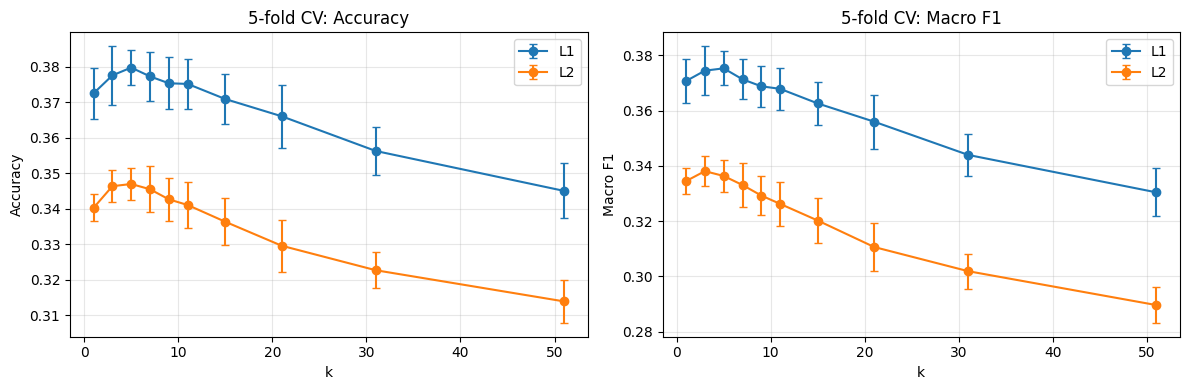

In [8]:
ranked = cv_summary.sort_values(
    ["accuracy_mean", "f1_macro_mean", "k", "metric"],
    ascending=[False, False, True, True],
)
best = ranked.iloc[0]
best_metric, best_k = str(best["metric"]), int(best["k"])
print(f"선택된 설정: metric={best_metric}, k={best_k}")
print(f"CV 정확도: {best['accuracy_mean']:.4f} ± {best['accuracy_std']:.4f}")
print(f"CV macro F1: {best['f1_macro_mean']:.4f} ± {best['f1_macro_std']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for metric in DISTANCE_METRICS:
    part = cv_summary[cv_summary["metric"] == metric].sort_values("k")
    for ax, score, title in zip(axes, ("accuracy", "f1_macro"), ("Accuracy", "Macro F1")):
        ax.errorbar(part["k"], part[f"{score}_mean"], yerr=part[f"{score}_std"],
                    marker="o", capsize=3, label=metric)
        ax.set(xlabel="k", ylabel=title, title=f"5-fold CV: {title}")
        ax.grid(alpha=0.3)
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()


## 8. 선택한 모델의 테스트 평가

선택한 조합으로 공식 **학습 데이터 50,000장 전체**를 사용하고, 지금까지 따로 보관한 **테스트 데이터 10,000장 전체**를 한 번 평가합니다. 클래스별 지표와 혼동행렬도 함께 출력합니다.


,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,0.3921,0.456,0.3921,0.389


,class,precision,recall,f1,support
0,airplane,0.4500,0.544,0.4925,1000
1,automobile,0.6839,0.264,0.3810,1000
2,bird,0.2644,0.417,0.3236,1000
3,cat,0.3130,0.216,0.2556,1000
4,deer,0.2633,0.516,0.3486,1000
5,dog,0.4286,0.312,0.3611,1000
6,frog,0.3763,0.350,0.3627,1000
7,horse,0.6455,0.315,0.4234,1000
8,ship,0.4307,0.699,0.5330,1000
9,truck,0.7042,0.288,0.4088,1000


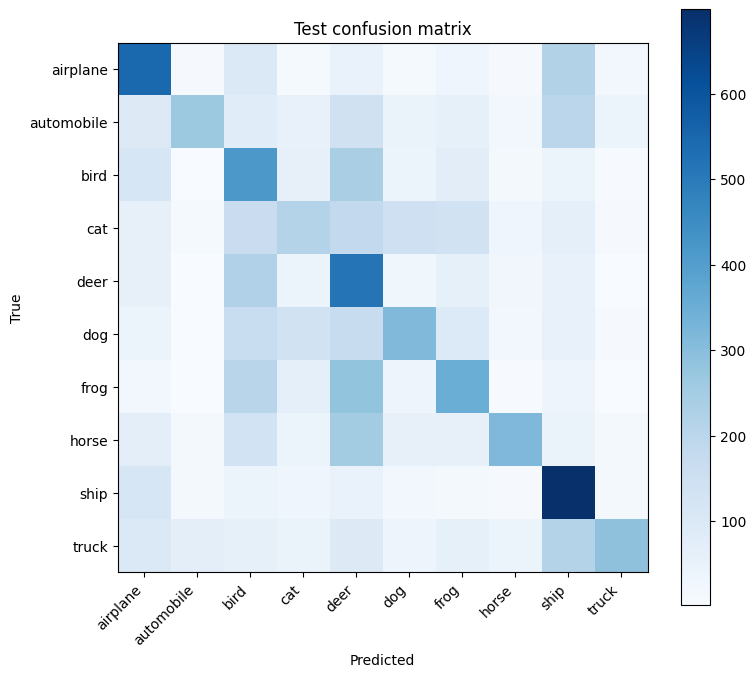

In [9]:
final_model = MODEL_CLASS().fit(X_train, y_train)
test_prediction = final_model.predict_many(X_test, (best_k,), best_metric, QUERY_BATCH_SIZE)[best_k]
test_scores, class_results, confusion = classification_metrics(y_test, test_prediction)
display(pd.DataFrame([test_scores]).rename(columns={
    "accuracy": "Accuracy", "precision_macro": "Precision (macro)",
    "recall_macro": "Recall (macro)", "f1_macro": "F1 (macro)",
}).round(4))
display(class_results.round(4))

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(confusion, cmap="Blues")
ax.set(xticks=np.arange(10), yticks=np.arange(10), xticklabels=class_names,
       yticklabels=class_names, xlabel="Predicted", ylabel="True", title="Test confusion matrix")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()


## 9. 결과 비교 및 설명

아래 문장은 실제 실행 결과로 채워집니다. 제출할 때는 교차검증 표, 그래프, 테스트 지표, 클래스별 결과와 함께 포함하세요. 픽셀 간 L1/L2 거리는 모양이나 위치의 작은 변화에도 민감하므로, CIFAR-10 이미지의 의미적 유사도를 완전히 표현하지 못한다는 한계가 있습니다.


In [10]:
# Colab에서 6~8번 셀 실행 후, 9번 코드 셀에 이 내용을 붙여 넣어 실행하세요.
from IPython.display import Markdown, display

score_labels = {
    "accuracy": "Accuracy",
    "precision_macro": "Precision (macro)",
    "recall_macro": "Recall (macro)",
    "f1_macro": "F1-score (macro)",
}

# 7번 셀과 동일한 선택 기준: 평균 정확도 → macro F1 → 작은 k → 거리 이름
ordered_cv = cv_summary.sort_values(
    ["accuracy_mean", "f1_macro_mean", "k", "metric"],
    ascending=[False, False, True, True],
)
metric_best = ordered_cv.drop_duplicates("metric").set_index("metric")
expected_best = ordered_cv.iloc[0]
if (str(expected_best["metric"]), int(expected_best["k"])) != (best_metric, best_k):
    raise ValueError("현재 교차검증 결과와 최종 선택이 다릅니다. 7번과 8번 셀을 다시 실행하세요.")

fit_sizes = sorted({len(fit_idx) for fit_idx, _ in folds})
validation_sizes = sorted({len(val_idx) for _, val_idx in folds})
fit_size_text = ", ".join(f"{size:,}" for size in fit_sizes)
validation_size_text = ", ".join(f"{size:,}" for size in validation_sizes)

display(Markdown("### 1. L1·L2별 최적 k와 교차검증 결과"))
display(Markdown(
    f"공식 학습 데이터 **{len(y_train):,}장**으로 {len(folds)}-fold 교차검증을 수행했습니다. "
    f"각 fold는 **학습 {fit_size_text}장 / 검증 {validation_size_text}장**으로 구성됩니다. "
    "아래 값은 각 거리 척도에서 선택한 k의 **fold별 점수 평균 ± 표준편차**입니다. "
    "정밀도·재현율·F1은 10개 클래스의 macro 평균이며, 모든 점수는 백분율로 표시합니다."
))

cv_report_rows = []
for metric in DISTANCE_METRICS:
    row = metric_best.loc[metric]
    report_row = {"거리 척도": metric, "최적 k": int(row["k"])}
    for score, label in score_labels.items():
        report_row[label] = f"{row[f'{score}_mean'] * 100:.2f}% ± {row[f'{score}_std'] * 100:.2f}%p"
    cv_report_rows.append(report_row)
display(pd.DataFrame(cv_report_rows))

display(Markdown("### 2. 최종 설정 선택"))
selected_cv = metric_best.loc[best_metric]
display(Markdown(
    f"최종 선택은 **{best_metric}, k={best_k}**입니다. "
    f"이 조합의 교차검증 평균 정확도는 **{selected_cv['accuracy_mean'] * 100:.2f}%**, "
    f"macro F1은 {selected_cv['f1_macro_mean'] * 100:.2f}%입니다. "
    "평균 정확도가 가장 높은 조합을 선택했으며, 동률이면 macro F1, 작은 k 순서로 비교했습니다. "
))

display(Markdown("### 3. 공식 테스트 데이터의 최종 평가"))
display(Markdown(
    f"선택한 **{best_metric}, k={best_k}**에 공식 학습 데이터 **{len(y_train):,}장 전체**를 "
    f"이웃 후보로 사용하고, 별도로 보관한 공식 테스트 데이터 **{len(y_test):,}장**을 평가했습니다. "
    "아래 값은 8번 셀에서 계산한 실제 테스트 점수입니다."
))
test_report_row = {"거리 척도": best_metric, "k": best_k}
test_report_row.update({label: f"{test_scores[score] * 100:.2f}%" for score, label in score_labels.items()})
display(pd.DataFrame([test_report_row]))

display(Markdown("### 4. 실험 비교 및 설명"))
comparison = []
l1 = metric_best.loc["L1"]
l2 = metric_best.loc["L2"]
accuracy_difference = float(l1["accuracy_mean"] - l2["accuracy_mean"])
if np.isclose(accuracy_difference, 0.0, rtol=0.0, atol=1e-12):
    comparison.append("L1과 L2는 각각의 최적 k에서 교차검증 평균 정확도가 같았습니다.")
else:
    better_metric = "L1" if accuracy_difference > 0 else "L2"
    comparison.append(
        f"각 거리 척도의 최적 k끼리 비교하면, {better_metric}의 교차검증 평균 정확도가 "
        f"L2보다 {abs(accuracy_difference) * 100:.2f}%p 높았습니다. "
    )

for metric in DISTANCE_METRICS:
    row = metric_best.loc[metric]
    baseline = cv_summary[(cv_summary["metric"] == metric) & (cv_summary["k"] == 1)]
    if not baseline.empty:
        improvement = float(row["accuracy_mean"] - baseline.iloc[0]["accuracy_mean"]) * 100
        if int(row["k"]) == 1:
            comparison.append(f"{metric}에서는 비교한 k 중 k=1이 선택되었습니다.")
        else:
            comparison.append(
                f"{metric}에서는 k={int(row['k'])}가 선택되었고, "
                f"k=1 대비 평균 정확도 차이는 {improvement:+.2f}%p였습니다."
            )

test_cv_difference = float(test_scores["accuracy"] - selected_cv["accuracy_mean"]) * 100
comparison.append(
    f"최종 테스트 정확도와 선택된 설정의 교차검증 평균 정확도의 차이는 "
    f"{test_cv_difference:+.2f}%p입니다. 검증 시와 최종 평가 시에는 학습 이미지 수와 "
    "평가 이미지가 모두 달라지므로, 이 차이만으로 성능 변화의 원인을 단정할 수 없습니다."
)
comparison.append(
    "k가 커지면 개별 이웃의 영향이 줄어들지만, 다른 클래스의 이웃이 더 많이 포함될 수 있어 "
    "정확도가 계속 증가하지는 않습니다. 동률은 동률인 클래스 중 가장 가까운 이웃으로 결정합니다."
)
comparison.append(
    "L1은 픽셀별 절댓값 차이를 합하고, L2는 제곱 차이를 이용하므로 큰 픽셀 차이에 더 민감합니다. "
    "두 방식 모두 배경·조명·물체 위치 등의 영향을 받는다는 한계가 있습니다."
)
display(Markdown("\n\n".join(f"- {sentence}" for sentence in comparison)))

### 1. L1·L2별 최적 k와 교차검증 결과

공식 학습 데이터 **50,000장**으로 5-fold 교차검증을 수행했습니다. 각 fold는 **학습 40,000장 / 검증 10,000장**으로 구성됩니다. 아래 값은 각 거리 척도에서 선택한 k의 **fold별 점수 평균 ± 표준편차**입니다. 정밀도·재현율·F1은 10개 클래스의 macro 평균이며, 모든 점수는 백분율로 표시합니다.

,거리 척도,최적 k,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,L1,5,37.98% ± 0.50%p,44.48% ± 0.81%p,37.98% ± 0.50%p,37.52% ± 0.62%p
1,L2,5,34.70% ± 0.44%p,43.12% ± 0.86%p,34.70% ± 0.44%p,33.63% ± 0.57%p


### 2. 최종 설정 선택

최종 선택은 **L1, k=5**입니다. 이 조합의 교차검증 평균 정확도는 **37.98%**, macro F1은 37.52%입니다. 평균 정확도가 가장 높은 조합을 선택했으며, 동률이면 macro F1, 작은 k 순서로 비교했습니다. 

### 3. 공식 테스트 데이터의 최종 평가

선택한 **L1, k=5**에 공식 학습 데이터 **50,000장 전체**를 이웃 후보로 사용하고, 별도로 보관한 공식 테스트 데이터 **10,000장**을 평가했습니다. 아래 값은 8번 셀에서 계산한 실제 테스트 점수입니다.

,거리 척도,k,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,L1,5,39.21%,45.60%,39.21%,38.90%


### 4. 실험 비교 및 설명

- 각 거리 척도의 최적 k끼리 비교하면, L1의 교차검증 평균 정확도가 L2보다 3.28%p 높았습니다. 

- L1에서는 k=5가 선택되었고, k=1 대비 평균 정확도 차이는 +0.73%p였습니다.

- L2에서는 k=5가 선택되었고, k=1 대비 평균 정확도 차이는 +0.67%p였습니다.

- 최종 테스트 정확도와 선택된 설정의 교차검증 평균 정확도의 차이는 +1.23%p입니다. 검증 시와 최종 평가 시에는 학습 이미지 수와 평가 이미지가 모두 달라지므로, 이 차이만으로 성능 변화의 원인을 단정할 수 없습니다.

- k가 커지면 개별 이웃의 영향이 줄어들지만, 다른 클래스의 이웃이 더 많이 포함될 수 있어 정확도가 계속 증가하지는 않습니다. 동률은 동률인 클래스 중 가장 가까운 이웃으로 결정합니다.

- L1은 픽셀별 절댓값 차이를 합하고, L2는 제곱 차이를 이용하므로 큰 픽셀 차이에 더 민감합니다. 두 방식 모두 배경·조명·물체 위치 등의 영향을 받는다는 한계가 있습니다.

In [13]:
_en_score_labels = {
    "accuracy": "Accuracy", "precision_macro": "Precision (macro)",
    "recall_macro": "Recall (macro)", "f1_macro": "F1-score (macro)",
}
_en_ordered = cv_summary.sort_values(
    ["accuracy_mean", "f1_macro_mean", "k", "metric"],
    ascending=[False, False, True, True],
)
_en_metric_best = _en_ordered.drop_duplicates("metric").set_index("metric")
_en_selected_cv = cv_summary[
    (cv_summary["metric"] == best_metric) & (cv_summary["k"] == best_k)
].iloc[0]
_en_fit_size_text = ", ".join(f"{size:,}" for size in sorted({len(t) for t, _ in folds}))
_en_validation_size_text = ", ".join(f"{size:,}" for size in sorted({len(v) for _, v in folds}))
_en_accuracy_difference = float(
    _en_metric_best.loc["L1", "accuracy_mean"] - _en_metric_best.loc["L2", "accuracy_mean"]
)
_en_test_cv_difference = float(test_scores["accuracy"] - _en_selected_cv["accuracy_mean"]) * 100

# English version
display(Markdown("---\n\n## Results and discussion"))

display(Markdown("### 1. Best k and cross-validation results for L1 and L2"))
display(Markdown(
    f"We performed **{len(folds)}-fold cross-validation** on all **{len(y_train):,} official training images**. "
    f"Each fold used **{_en_fit_size_text} images for training and {_en_validation_size_text} images for validation**. "
    "The table reports the **mean ± standard deviation across folds** for the selected k of each distance metric. "
    "Precision, recall, and F1-score are macro averages over the 10 classes. "
    "Scores are shown as percentages; standard deviations are shown in percentage points (pp)."
))

english_cv_rows = []
for metric in DISTANCE_METRICS:
    row = _en_metric_best.loc[metric]
    english_row = {"Distance metric": metric, "Best k": int(row["k"])}
    for score, label in _en_score_labels.items():
        english_row[label] = f"{row[f'{score}_mean'] * 100:.2f}% ± {row[f'{score}_std'] * 100:.2f} pp"
    english_cv_rows.append(english_row)
display(pd.DataFrame(english_cv_rows))

display(Markdown("### 2. Final configuration selection"))
display(Markdown(
    f"The final configuration was **{best_metric}, k={best_k}**. "
    f"Its mean cross-validation accuracy was **{_en_selected_cv['accuracy_mean'] * 100:.2f}%**, "
    f"and its macro F1-score was **{_en_selected_cv['f1_macro_mean'] * 100:.2f}%**. "
    "We selected the configuration with the highest mean cross-validation accuracy. "
    "Ties were resolved by higher macro F1-score, followed by smaller k."
))

display(Markdown("### 3. Final evaluation on the official test set"))
display(Markdown(
    f"Using the selected configuration, **{best_metric}, k={best_k}**, we stored all "
    f"**{len(y_train):,} official training images** as candidate neighbors and evaluated "
    f"the separate **{len(y_test):,} official test images**. "
    "The table shows the test scores computed in Section 8."
))
english_test_row = {"Distance metric": best_metric, "k": best_k}
english_test_row.update({label: f"{test_scores[score] * 100:.2f}%" for score, label in _en_score_labels.items()})
display(pd.DataFrame([english_test_row]))

display(Markdown("### 4. Comparison and discussion"))
english_comparison = []
if np.isclose(_en_accuracy_difference, 0.0, rtol=0.0, atol=1e-12):
    english_comparison.append(
        "L1 and L2 achieved the same mean cross-validation accuracy at their respective best k values."
    )
else:
    better_metric = "L1" if _en_accuracy_difference > 0 else "L2"
    other_metric = "L2" if _en_accuracy_difference > 0 else "L1"
    english_comparison.append(
        f"At their respective best k values, {better_metric} achieved a mean cross-validation accuracy "
        f"{abs(_en_accuracy_difference) * 100:.2f}%p higher than {other_metric}. "
    )

for metric in DISTANCE_METRICS:
    row = _en_metric_best.loc[metric]
    baseline = cv_summary[(cv_summary["metric"] == metric) & (cv_summary["k"] == 1)]
    if not baseline.empty:
        improvement = float(row["accuracy_mean"] - baseline.iloc[0]["accuracy_mean"]) * 100
        if int(row["k"]) == 1:
            english_comparison.append(f"For {metric}, k=1 was selected among the tested k values.")
        else:
            english_comparison.append(
                f"For {metric}, k={int(row['k'])} was selected. Its mean accuracy differed from "
                f"the k=1 result by {improvement:+.2f}%p."
            )

english_comparison.append(
    f"(The final test accuracy - the selected configuration's mean cross-validation accuracy) was "
    f"{_en_test_cv_difference:+.2f}%p. "
    "We cannot tell whether the accuracy changed because more training images were used "
    "or because the model was evaluated on different images."
)
english_comparison.append(
    "Increasing k reduces the influence of individual neighbors, but may include more neighbors from "
    "other classes; accuracy therefore does not necessarily increase with k. Voting ties are resolved "
    "by choosing the class of the closest neighbor among the classes tied for the most votes."
)
english_comparison.append(
    "L1 sums absolute pixel differences, while L2 uses squared differences and is more sensitive to "
    "large pixel differences. Both methods are affected by background, lighting, and object position."
)
display(Markdown("\n\n".join(f"- {sentence}" for sentence in english_comparison)))

---

## Results and discussion

### 1. Best k and cross-validation results for L1 and L2

We performed **5-fold cross-validation** on all **50,000 official training images**. Each fold used **40,000 images for training and 10,000 images for validation**. The table reports the **mean ± standard deviation across folds** for the selected k of each distance metric. Precision, recall, and F1-score are macro averages over the 10 classes. Scores are shown as percentages; standard deviations are shown in percentage points (pp).

,Distance metric,Best k,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,L1,5,37.98% ± 0.50 pp,44.48% ± 0.81 pp,37.98% ± 0.50 pp,37.52% ± 0.62 pp
1,L2,5,34.70% ± 0.44 pp,43.12% ± 0.86 pp,34.70% ± 0.44 pp,33.63% ± 0.57 pp


### 2. Final configuration selection

The final configuration was **L1, k=5**. Its mean cross-validation accuracy was **37.98%**, and its macro F1-score was **37.52%**. We selected the configuration with the highest mean cross-validation accuracy. Ties were resolved by higher macro F1-score, followed by smaller k.

### 3. Final evaluation on the official test set

Using the selected configuration, **L1, k=5**, we stored all **50,000 official training images** as candidate neighbors and evaluated the separate **10,000 official test images**. The table shows the test scores computed in Section 8.

,Distance metric,k,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,L1,5,39.21%,45.60%,39.21%,38.90%


### 4. Comparison and discussion

- At their respective best k values, L1 achieved a mean cross-validation accuracy 3.28%p higher than L2. 

- For L1, k=5 was selected. Its mean accuracy differed from the k=1 result by +0.73%p.

- For L2, k=5 was selected. Its mean accuracy differed from the k=1 result by +0.67%p.

- (The final test accuracy - the selected configuration's mean cross-validation accuracy) was +1.23%p. We cannot tell whether the accuracy changed because more training images were used or because the model was evaluated on different images.

- Increasing k reduces the influence of individual neighbors, but may include more neighbors from other classes; accuracy therefore does not necessarily increase with k. Voting ties are resolved by choosing the class of the closest neighbor among the classes tied for the most votes.

- L1 sums absolute pixel differences, while L2 uses squared differences and is more sensitive to large pixel differences. Both methods are affected by background, lighting, and object position.